# Inference + evaluation (quick)

Loads the **saved** crime-risk model (`models/artifacts/xgb_risk.ubj`), scores a few cells and hours, and evaluates it on held-out years. No training happens here.

- **Held out:** the model trained on 2020-04 to 2022-12. 2023 is the test year, 2024 is an extra out-of-time check.
- **H3 resolution:** whatever the saved artifacts say (`model_meta.json["h3_res"]`, printed below). When this notebook was written the artifacts were **res 9**.
- Metrics use the eval frame's weights, so they equal what the full cell x hour x day grid would give.

Run with *Restart & Run All*. Takes about a minute.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd()
if ROOT.name == "algorithm":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import h3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from algorithm.common import config, geo
from algorithm.scoring import score
from algorithm.models.train_xgb import evaluate, calibration_bins

booster, meta, hist = score._load()   # model + metadata + crime history (~3 s)
saved = json.loads((config.ARTIFACT_DIR / "metrics.json").read_text())

print("H3 resolution:", meta["h3_res"], "| trained at:", meta["trained_at"])
print("features:", len(meta["features"]), "| modelled cells:", meta["covered_cells"])
assert meta["h3_res"] == config.H3_RES, "artifacts and config disagree on H3 resolution"


H3 resolution: 9 | trained at: 2026-11-15T03:43:45+00:00
features: 16 | modelled cells: 1451


## 1. Inference on a few cells and hours

`risk` is the 0..1 percentile vs all 2023 cell-hours; `prob` is the calibrated chance of at least one reported incident in that cell during that hour.

In [2]:
places = {
    "USC Village":        (34.0256, -118.2853),
    "Leavey Library":     (34.0218, -118.2829),
    "Exposition Park":    (34.0164, -118.2879),
    "Figueroa & Adams":   (34.0330, -118.2740),
}
date = "2026-11-14"
rows = []
for name, (lat, lng) in places.items():
    cell = h3.latlng_to_cell(lat, lng, meta["h3_res"])
    for hour in (3, 12, 22):
        e = score.explain_cell(cell, hour, date, top_k=1)
        rows.append({"place": name, "cell": cell, "hour": hour, "status": e["status"],
                     "risk": e["risk"], "prob": e["prob"],
                     "top factor": e["factors"][0]["label"] if e.get("factors") else None})
pd.DataFrame(rows).round(4)

,place,cell,hour,status,risk,prob,top factor
0,USC Village,8929a1d647bffff,3,ok,0.3206,0.0032,time of day
1,USC Village,8929a1d647bffff,12,ok,0.7961,0.0104,time of day
2,USC Village,8929a1d647bffff,22,ok,0.7249,0.0085,time of day
3,Leavey Library,8929a1d6443ffff,3,ok,0.3293,0.0033,time of day
4,Leavey Library,8929a1d6443ffff,12,ok,0.7007,0.0080,time of day
5,Leavey Library,8929a1d6443ffff,22,ok,0.8514,0.0125,long-run rate here at this hour
6,Exposition Park,8929a1d641bffff,3,ok,0.0299,0.0006,long-run incident rate here
7,Exposition Park,8929a1d641bffff,12,ok,0.1092,0.0014,long-run incident rate here
8,Exposition Park,8929a1d641bffff,22,ok,0.1090,0.0014,long-run incident rate here
9,Figueroa & Adams,8929a1d6607ffff,3,ok,0.6334,0.0068,time of day


## 2. Evaluate on held-out 2023 and 2024

In [3]:
def predict_served(frame):
    raw = booster.predict(xgb.DMatrix(frame[meta["features"]]))
    prob = score._prob(raw, meta["neg_rate"])                                   # undo negative sampling
    return prob * geo.bluelight_factor(frame["dist_bluelight_m"].to_numpy())   # what score_cell serves

results, frames = {}, {}
for split, (a, b) in {"2023 (test)": (config.TEST_START, config.TEST_END),
                      "2024 (extra)": (config.EXTRA_START, config.EXTRA_END)}.items():
    g, _, _ = hist.eval_frame(a, b)
    y, w, p = g["y"].to_numpy(), g["w"].to_numpy(), predict_served(g)
    results[split] = evaluate(y, p, split, w)
    frames[split] = (y, w, p)

summary = pd.DataFrame(results).T[["base_rate", "mean_pred", "auc", "pr_auc", "top10pct_capture", "brier"]]
summary

  2023 (test)                  AUC 0.746  PR-AUC 0.0296  (base 0.0069)  top-10% capture 36.6%


  2024 (extra)                 AUC 0.758  PR-AUC 0.0189  (base 0.0036)  top-10% capture 39.0%


,base_rate,mean_pred,auc,pr_auc,top10pct_capture,brier
2023 (test),0.006886,0.007568,0.745556,0.029603,0.365829,0.006765
2024 (extra),0.003625,0.006717,0.758052,0.018921,0.389779,0.003612


Check against the numbers saved at training time (`metrics.json`, served model). They should match closely.

In [4]:
check = pd.DataFrame({
    "saved AUC": [saved["test_2023"]["xgboost_served"]["auc"], saved["extra_2024"]["xgboost_served"]["auc"]],
    "this run AUC": [results["2023 (test)"]["auc"], results["2024 (extra)"]["auc"]],
}, index=["2023 (test)", "2024 (extra)"])
check["diff"] = check["this run AUC"] - check["saved AUC"]
check.round(4)

,saved AUC,this run AUC,diff
2023 (test),0.7457,0.7456,-0.0001
2024 (extra),0.7583,0.7581,-0.0003


## 3. Calibration (2023)

Points on the diagonal mean a predicted 1% really happens about 1% of the time.

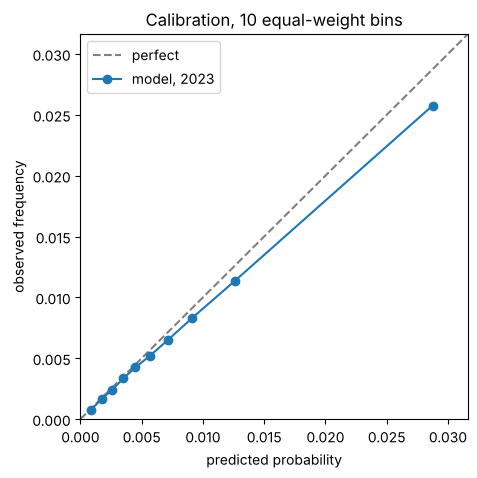

,mean_pred,observed
0,0.00083,0.00074
1,0.00175,0.00167
2,0.00260,0.00242
3,0.00350,0.00334
4,0.00448,0.00424
5,0.00566,0.00519
6,0.00712,0.00648
7,0.00914,0.00832
8,0.01260,0.01135
9,0.02875,0.02576


In [5]:
y, w, p = frames["2023 (test)"]
mean_pred, observed = calibration_bins(y, p, w, n_bins=10)
hi = max(max(mean_pred), max(observed)) * 1.1
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, hi], [0, hi], "--", color="grey", label="perfect")
ax.plot(mean_pred, observed, marker="o", label="model, 2023")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.legend(); ax.set_title("Calibration, 10 equal-weight bins")
plt.show()
pd.DataFrame({"mean_pred": mean_pred, "observed": observed}).round(5)

## 4. Confusion matrix, accuracy, precision, recall (2023)

The model outputs a probability, so these need a cutoff. We flag a cell-hour as **"high risk"** when it is in the riskiest X% of 2023 cell-hours (same idea as the `risk` percentile that `score_cell` returns: top 10% means `risk >= 0.9`).

Only about 0.7% of cell-hours have an incident, so **accuracy is misleading**: predicting "no incident" everywhere already scores 99.3%. Precision and recall are the useful numbers. Counts are grid-weighted, so they are real 2023 cell-hours, not sampled rows.

In [6]:
from sklearn.metrics import confusion_matrix

y, w, p = frames["2023 (test)"]

def threshold_for_top(p, w, pct):
    o = np.argsort(-p)
    cw = np.cumsum(w[o]) / w.sum()
    return p[o][np.searchsorted(cw, pct)]

rows = []
for pct in (0.05, 0.10, 0.20, 0.30):
    t = threshold_for_top(p, w, pct)
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, sample_weight=w).ravel()
    rows.append({"flag riskiest": f"{pct:.0%}", "prob cutoff": t,
                 "accuracy": (tp + tn) / (tp + tn + fp + fn),
                 "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                 "lift vs base rate": (tp / (tp + fp)) / np.average(y, weights=w)})
print(f"Always predicting 'no incident' gives accuracy {1 - np.average(y, weights=w):.4f}")
pd.DataFrame(rows).round(4)

Always predicting 'no incident' gives accuracy 0.9931


,flag riskiest,prob cutoff,accuracy,precision,recall,lift vs base rate
0,5%,0.0213,0.9465,0.0342,0.2482,4.9620
1,10%,0.0151,0.8981,0.0252,0.3659,3.6574
2,20%,0.0104,0.8003,0.0182,0.5286,2.6423
3,30%,0.0080,0.7025,0.0149,0.6488,2.1661


2023 cell-hours, high risk = riskiest 10% (prob >= 0.0151)
                     predicted: low risk  predicted: high risk
actual: no incident             11383765               1239465
actual: incident                   55506                 32024


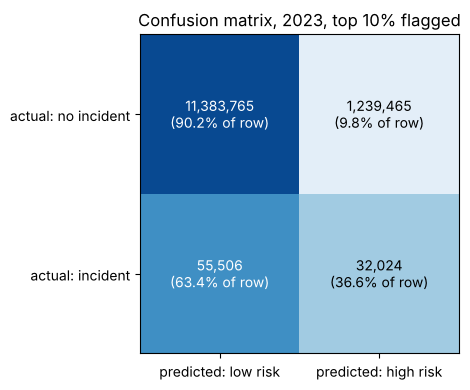

In [7]:
pct = 0.10   # change to look at another cutoff
t = threshold_for_top(p, w, pct)
cm = confusion_matrix(y, (p >= t).astype(int), sample_weight=w)
cm_df = pd.DataFrame(cm.round().astype(int),
                     index=["actual: no incident", "actual: incident"],
                     columns=["predicted: low risk", "predicted: high risk"])
print(f"2023 cell-hours, high risk = riskiest {pct:.0%} (prob >= {t:.4f})")
print(cm_df.to_string())

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,.0f}\n({cm[i, j] / cm[i].sum():.1%} of row)", ha="center", va="center",
                color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
ax.set_xticks([0, 1], cm_df.columns); ax.set_yticks([0, 1], cm_df.index)
ax.set_title(f"Confusion matrix, 2023, top {pct:.0%} flagged")
plt.tight_layout(); plt.show()